# 1. Data Loading and Overview

In [2]:
import pandas as pd
import numpy as np



In [3]:
store=pd.read_csv(r'C:\Users\HRITHIK\Downloads\Global Superstore Retail Dataset.csv')
store.info()


<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  str    
 1   City            51290 non-null  str    
 2   Country         51290 non-null  str    
 3   Customer.ID     51290 non-null  str    
 4   Customer.Name   51290 non-null  str    
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  str    
 7   记录数             51290 non-null  int64  
 8   Order.Date      51290 non-null  str    
 9   Order.ID        51290 non-null  str    
 10  Order.Priority  51290 non-null  str    
 11  Product.ID      51290 non-null  str    
 12  Product.Name    51290 non-null  str    
 13  Profit          51290 non-null  float64
 14  Quantity        51290 non-null  int64  
 15  Region          51290 non-null  str    
 16  Row.ID          51290 non-null  int64  
 17  Sales           51290 non-null  int64  
 1

# 2. Data Quality Checks



In [4]:

store.isnull().sum()

Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
记录数               0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     0
State             0
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64

In [12]:
store.duplicated().sum()

np.int64(0)

In [5]:
store.dtypes

Category              str
City                  str
Country               str
Customer.ID           str
Customer.Name         str
Discount          float64
Market                str
记录数                 int64
Order.Date            str
Order.ID              str
Order.Priority        str
Product.ID            str
Product.Name          str
Profit            float64
Quantity            int64
Region                str
Row.ID              int64
Sales               int64
Segment               str
Ship.Date             str
Ship.Mode             str
Shipping.Cost     float64
State                 str
Sub.Category          str
Year                int64
Market2               str
weeknum             int64
dtype: object

# 3. Data Cleaning and Preparation


In [4]:

store['Order.Date'] = pd.to_datetime(store['Order.Date'])
store['Ship.Date'] = pd.to_datetime(store['Ship.Date'])




In [7]:




store[['Order.Date', 'Ship.Date']].dtypes


Order.Date    datetime64[us]
Ship.Date     datetime64[us]
dtype: object

# 4. Shipping-Days Analysis



In [ ]:

# Shipping analysis
store['Shipping.Days'] = (
    store['Ship.Date'] - store['Order.Date']
).dt.days

print(store["Shipping.Days"].head(10))




0    2
1    5
2    4
3    4
4    4
5    0
6    7
7    4
8    4
9    5
Name: Shipping.Days, dtype: int64


In [ ]:
#Summary
print("Minimum shipping days:", store['Shipping.Days'].min())
print("Maximum shipping days:", store['Shipping.Days'].max())
print("Average shipping days:", store['Shipping.Days'].mean())
print("Negative shipping days:", (store['Shipping.Days'] < 0).sum())


Minimum shipping days: 0
Maximum shipping days: 7
Average shipping days: 3.96937024761162
Negative shipping days: 0


# 5. Descriptive Statistics and Unusual Values


In [20]:

store[['Sales', 'Profit', 'Discount', 'Quantity']].describe()


,Sales,Profit,Discount,Quantity
count,51290.000000,51290.000000,51290.000000,51290.000000
mean,246.498440,28.610982,0.142908,3.476545
std,487.567175,174.340972,0.212280,2.278766
min,0.000000,-6599.978000,0.000000,1.000000
25%,31.000000,0.000000,0.000000,2.000000
50%,85.000000,9.240000,0.000000,3.000000
75%,251.000000,36.810000,0.200000,5.000000
max,22638.000000,8399.976000,0.850000,14.000000


# 6. Discount-Group Analysis



In [ ]:

#  Discount groups for analysis
store['Discount.Group'] = pd.cut(
    store['Discount'],
    bins=[-0.001, 0, 0.2, 0.5, 1],
    labels=['No Discount', 'Low (0-20%)',
            'Medium (20-50%)', 'High (50%+)'],
    include_lowest=True
)

discount_analysis = store.groupby(
    'Discount.Group',
    observed=False
).agg(
    Transactions=('Profit', 'size'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Loss_Making_Rows=('Profit', lambda x: (x < 0).sum())
)

discount_analysis['Loss_Percentage'] = (
    discount_analysis['Loss_Making_Rows']
    / discount_analysis['Transactions'] * 100
).round(2)

discount_analysis


,Transactions,Total_Sales,Total_Profit,Average_Profit,Loss_Making_Rows,Loss_Percentage
Discount.Group,,,,,,
No Discount,29009,6992734,1.770695e+06,61.039514,0,0.00
Low (0-20%),10953,3719929,5.114441e+05,46.694431,2364,21.58
Medium (20-50%),7156,1558618,-4.021004e+05,-56.190669,6008,83.96
High (50%+),4172,371624,-4.125817e+05,-98.893015,4172,100.00


# 7. Sub-Category Profitability Analysis



In [23]:

subcategory_analysis = store.groupby('Sub.Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Transactions=('Profit', 'size'),
    Loss_Making_Rows=('Profit', lambda x: (x < 0).sum())
)

subcategory_analysis['Loss_Percentage'] = (
    subcategory_analysis['Loss_Making_Rows']
    / subcategory_analysis['Transactions'] * 100
).round(2)

subcategory_analysis = subcategory_analysis.sort_values(
    by='Total_Profit',
    ascending=True
)

subcategory_analysis


,Total_Sales,Total_Profit,Average_Profit,Transactions,Loss_Making_Rows,Loss_Percentage
Sub.Category,,,,,,
Tables,757034,-64083.38870,-74.429023,861,496,57.61
Fasteners,83254,11525.42410,4.762572,2420,612,25.29
Labels,73433,15010.51200,5.759982,2606,520,19.95
Supplies,243090,22583.26310,9.312686,2425,589,24.29
Envelopes,170926,29601.11630,12.156516,2435,555,22.79
Furnishings,385609,46967.42550,14.816223,3170,804,25.36
Art,372163,57953.91090,11.868505,4883,910,18.64
Machines,779071,58867.87300,39.614989,1486,454,30.55
Paper,244307,59207.68270,16.734789,3538,527,14.90


# 8. Tables Discount Analysis


In [24]:

tables_discount = store[
    store['Sub.Category'] == 'Tables'
].groupby('Discount').agg(
    Transactions=('Profit', 'size'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Loss_Making_Rows=('Profit', lambda x: (x < 0).sum())
)

tables_discount['Loss_Percentage'] = (
    tables_discount['Loss_Making_Rows']
    / tables_discount['Transactions'] * 100
).round(2)

tables_discount.sort_index()


,Transactions,Total_Sales,Total_Profit,Average_Profit,Loss_Making_Rows,Loss_Percentage
Discount,,,,,,
0.00,208,261807,60447.1997,290.611537,0,0.00
0.10,3,3481,795.0270,265.009000,0,0.00
0.20,183,157721,7215.5360,39.429158,72,39.34
0.30,116,104747,-11960.4786,-103.107574,90,77.59
0.35,45,54159,-9122.6490,-202.725533,34,75.56
0.40,85,52162,-17105.1808,-201.237421,81,95.29
0.45,13,8032,-3596.3026,-276.638662,13,100.00
0.47,34,32502,-10680.2751,-314.125738,33,97.06
0.50,52,26505,-15049.8623,-289.420429,51,98.08


# 9. Overall Tables Performance



In [25]:

tables = store[store['Sub.Category'] == 'Tables']

print("Total Tables sales:", tables['Sales'].sum())
print("Total Tables profit:", tables['Profit'].sum())
print("Total Tables transactions:", len(tables))
print("Loss-making rows:", (tables['Profit'] < 0).sum())
print(
    "Loss-making percentage:",
    round((tables['Profit'] < 0).mean() * 100, 2), "%"
)


Total Tables sales: 757034
Total Tables profit: -64083.38869999998
Total Tables transactions: 861
Loss-making rows: 496
Loss-making percentage: 57.61 %


# 10. Tables Performance by Region

In [26]:

tables_region = tables.groupby('Region').agg(
    Transactions=('Profit', 'size'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Loss_Making_Rows=('Profit', lambda x: (x < 0).sum())
)

tables_region['Loss_Percentage'] = (
    tables_region['Loss_Making_Rows']
    / tables_region['Transactions'] * 100
).round(2)

tables_region.sort_values('Total_Profit')


,Transactions,Total_Sales,Total_Profit,Average_Profit,Loss_Making_Rows,Loss_Percentage
Region,,,,,,
South,132,104894,-27012.3219,-204.638802,91,68.94
Central,166,133126,-21550.1069,-129.819921,109,65.66
Southeast Asia,59,52452,-18618.3051,-315.564493,55,93.22
East,80,39142,-11025.3801,-137.817251,78,97.50
North Asia,42,54299,-5470.5780,-130.251857,24,57.14
Oceania,53,66833,-229.7190,-4.334321,29,54.72
Caribbean,27,23660,63.3880,2.347704,11,40.74
Canada,2,850,300.1800,150.090000,0,0.00
West,116,84755,1482.6073,12.781097,49,42.24



# 11. Regional Summary for Priority Regions








In [27]:

priority_regions = ['South', 'Central', 'Southeast Asia', 'East']

regional_discount = tables[
    tables['Region'].isin(priority_regions)
].groupby(['Region', 'Discount']).agg(
    Transactions=('Profit', 'size'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Loss_Making_Rows=('Profit', lambda x: (x < 0).sum())
)

regional_discount['Loss_Percentage'] = (
    regional_discount['Loss_Making_Rows']
    / regional_discount['Transactions'] * 100
).round(2)

regional_discount.sort_values(
    ['Region', 'Discount']
)


Transactions  Total_Profit  Average_Profit  \
Region         Discount                                               
Central        0.00                22     3015.3709      137.062314   
               0.20                28     2983.2360      106.544143   
               0.30                33    -2216.6766      -67.172018   
               0.35                45    -9122.6490     -202.725533   
               0.45                 2    -1103.1915     -551.595750   
               0.50                18    -4309.7447     -239.430261   
               0.70                16    -7727.7940     -482.987125   
               0.85                 2    -3068.6580    -1534.329000   
East           0.30                21    -1185.6510      -56.459571   
               0.40                59    -9839.7291     -166.775069   
South          0.00                24     4217.7209      175.738371   
               0.20                32      579.5560       18.111125   
               0.40                16    -6347.6677     -396.729231   
               0.45                11    -2493.1111     -226.646464   
               0.50                13    -5811.6900     -447.053077   
               0.60                15    -6463.5480     -430.903200   
               0.70                20   -10605.8460     -530.292300   
               0.80                 1      -87.7360      -87.736000   
Southeast Asia 0.00                 3     1526.1900      508.730000   
               0.47                34   -10680.2751     -314.125738   
               0.55                10    -3150.6720     -315.067200   
               0.57                12    -6313.5480     -526.129000   

                         Loss_Making_Rows  Loss_Percentage  
Region         Discount                                     
Central        0.00                     0             0.00  
               0.20                     6            21.43  
               0.30                    31            93.94  
               0.35                    34            75.56  
               0.45                     2           100.00  
               0.50                    18           100.00  
               0.70                    16           100.00  
               0.85                     2           100.00  
East           0.30                    19            90.48  
               0.40                    59           100.00  
South          0.00                     0             0.00  
               0.20                    16            50.00  
               0.40                    16           100.00  
               0.45                    11           100.00  
               0.50                    12            92.31  
               0.60                    15           100.00  
               0.70                    20           100.00  
               0.80                     1           100.00  
Southeast Asia 0.00                     0             0.00  
               0.47                    33            97.06  
               0.55                    10           100.00  
               0.57                    12           100.00


# 12. Combined Discount Analysis for Priority Regions




In [28]:
regional_summary = tables[
    tables['Region'].isin(priority_regions)
].groupby('Region').agg(
    Transactions=('Profit', 'size'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Loss_Making_Rows=('Profit', lambda x: (x < 0).sum())
)

regional_summary['Loss_Percentage'] = (
    regional_summary['Loss_Making_Rows']
    / regional_summary['Transactions'] * 100
).round(2)

regional_summary.sort_values('Total_Profit')

,Transactions,Total_Profit,Average_Profit,Loss_Making_Rows,Loss_Percentage
Region,,,,,
South,132,-27012.3219,-204.638802,91,68.94
Central,166,-21550.1069,-129.819921,109,65.66
Southeast Asia,59,-18618.3051,-315.564493,55,93.22
East,80,-11025.3801,-137.817251,78,97.50


## 13. Tables: Discount Patterns Across Selected Regions



In [29]:

regional_discount_totals = tables[
    tables['Region'].isin(priority_regions)
].groupby('Discount').agg(
    Transactions=('Profit', 'size'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Loss_Making_Rows=('Profit', lambda x: (x < 0).sum())
)

regional_discount_totals['Loss_Percentage'] = (
    regional_discount_totals['Loss_Making_Rows']
    / regional_discount_totals['Transactions'] * 100
).round(2)

regional_discount_totals.sort_values('Total_Profit')

,Transactions,Total_Profit,Average_Profit,Loss_Making_Rows,Loss_Percentage
Discount,,,,,
0.70,36,-18333.6400,-509.267778,36,100.00
0.40,75,-16187.3968,-215.831957,75,100.00
0.47,34,-10680.2751,-314.125738,33,97.06
0.50,31,-10121.4347,-326.497894,30,96.77
0.35,45,-9122.6490,-202.725533,34,75.56
0.60,15,-6463.5480,-430.903200,15,100.00
0.57,12,-6313.5480,-526.129000,12,100.00
0.45,13,-3596.3026,-276.638662,13,100.00
0.30,54,-3402.3276,-63.006067,50,92.59


## 14. Tables: Product-Level Profitability


In [30]:

tables_product_analysis = tables.groupby('Product.Name').agg(
    Transactions=('Profit', 'size'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Average_Discount=('Discount', 'mean'),
    Loss_Making_Rows=('Profit', lambda x: (x < 0).sum())
)

tables_product_analysis['Loss_Percentage'] = (
    tables_product_analysis['Loss_Making_Rows']
    / tables_product_analysis['Transactions'] * 100
).round(2)

tables_product_analysis.sort_values('Total_Profit').head(10)

,Transactions,Total_Sales,Total_Profit,Average_Profit,Average_Discount,Loss_Making_Rows,Loss_Percentage
Product.Name,,,,,,,
"Bevis Round Table, Adjustable Height",5,5655,-3649.8940,-729.978800,0.460000,4,80.00
"Bevis Computer Table, Fully Assembled",13,11176,-3509.5638,-269.966446,0.353077,9,69.23
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,5,9918,-2876.1156,-575.223120,0.280000,4,80.00
"Bevis Wood Table, with Bottom Storage",10,11134,-2782.5880,-278.258800,0.320000,7,70.00
"Lesro Training Table, Rectangular",5,2712,-2581.2834,-516.256680,0.582000,5,100.00
"Barricks Conference Table, Rectangular",3,3664,-2487.9675,-829.322500,0.350000,2,66.67
"Bevis Conference Table, Fully Assembled",8,14885,-2443.0893,-305.386163,0.302500,4,50.00
"Lesro Round Table, Adjustable Height",5,3961,-2402.9760,-480.595200,0.434000,5,100.00
"Lesro Computer Table, Fully Assembled",7,7224,-2322.8380,-331.834000,0.400000,4,57.14


## 15. Tables: Product and Discount-Level Analysis



In [31]:

product_discount_analysis = tables.groupby(
    ['Product.Name', 'Discount']
).agg(
    Transactions=('Profit', 'size'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Loss_Making_Rows=('Profit', lambda x: (x < 0).sum())
)

product_discount_analysis['Loss_Percentage'] = (
    product_discount_analysis['Loss_Making_Rows']
    / product_discount_analysis['Transactions'] * 100
).round(2)

product_discount_analysis.sort_values(
    'Total_Profit'
).head(15)

,,Transactions,Total_Profit,Average_Profit,Loss_Making_Rows,Loss_Percentage
Product.Name,Discount,,,,,
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,0.40,3,-3008.3508,-1002.783600,3,100.0
"Lesro Computer Table, Fully Assembled",0.70,3,-2798.4880,-932.829333,3,100.0
"Barricks Conference Table, Rectangular",0.70,1,-2750.2800,-2750.280000,1,100.0
"Hon Conference Table, Rectangular",0.80,1,-2380.3500,-2380.350000,1,100.0
"Bevis Wood Table, with Bottom Storage",0.30,4,-2113.6140,-528.403500,4,100.0
"Bevis Conference Table, Fully Assembled",0.85,1,-1924.5420,-1924.542000,1,100.0
"Barricks Conference Table, Adjustable Height",0.70,1,-1864.0950,-1864.095000,1,100.0
"Chromcraft Conference Table, with Bottom Storage",0.70,2,-1780.3560,-890.178000,2,100.0
"Bevis Round Table, Adjustable Height",0.60,1,-1779.7680,-1779.768000,1,100.0


## 16. Monthly Performance Analysis


In [32]:

store['Order.Month'] = store['Order.Date'].dt.to_period('M')

monthly_analysis = store.groupby('Order.Month').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

monthly_analysis


,Total_Sales,Total_Profit
Order.Month,,
2011-01,98902,8321.80096
2011-02,91152,12417.90698
2011-03,145726,15303.56826
2011-04,116927,12902.32438
2011-05,146762,12183.82870
2011-06,215214,23415.24702
2011-07,115518,5585.00352
2011-08,207570,23713.66772
2011-09,290230,35776.88394


## 17. Yearly Performance Analysis



In [33]:

yearly_analysis = store.groupby(
    store['Order.Date'].dt.year
).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

yearly_analysis


,Total_Sales,Total_Profit
Order.Date,,
2011,2259511,248940.81154
2012,2677493,307415.27910
2013,3405860,406935.23018
2014,4300041,504165.97046


## 18. Statistical Analysis: Discount and Profit


In [35]:

from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    store['Discount'],
    store['Profit']
)

print("Spearman correlation:", round(correlation, 4))
print("P-value:", p_value)


Spearman correlation: -0.596
P-value: 0.0


## 19. Yearly Performance Visualizations



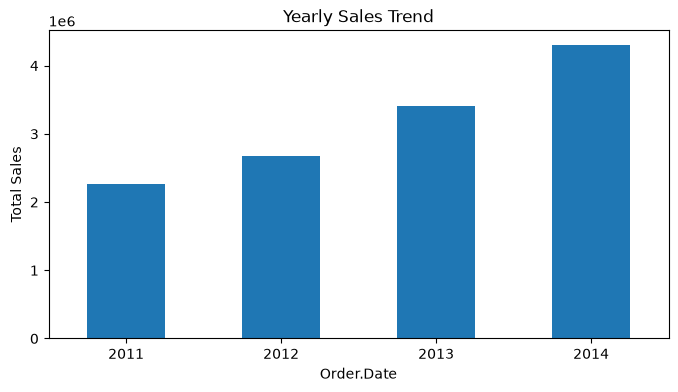

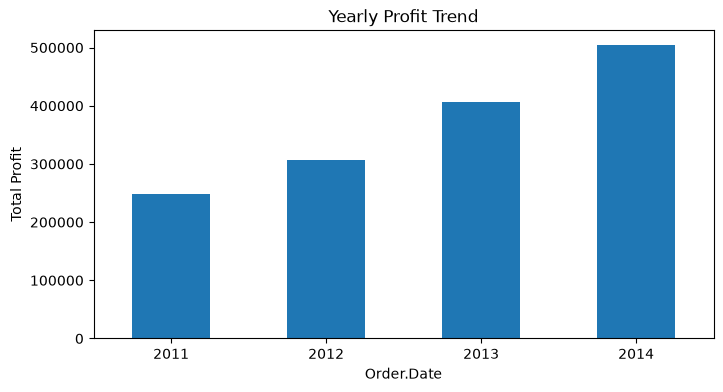

In [36]:

import matplotlib.pyplot as plt

yearly_analysis['Total_Sales'].plot(
    kind='bar',
    figsize=(8, 4),
    title='Yearly Sales Trend'
)
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

yearly_analysis['Total_Profit'].plot(
    kind='bar',
    figsize=(8, 4),
    title='Yearly Profit Trend'
)
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.show()
